# TUGAS DATA WRANGLING & PIPELINE ANALYSIS DATA
**Mata Kuliah:** Data Wrangling  
**Program Studi:** S1 Sains Data, Fakultas Matematika dan Ilmu Pengetahuan Alam, Universitas Negeri Surabaya (UNESA)  
**Dosen Pengampu:** Dr. Belgis Ainatul Iza, S.Si., M.Mat.  
**Identitas Mahasiswa:**
- **Nama:** Muhammad Irfan Pratama
- **NIM:** 25031554135
- **Kelas:** 2025B

---



# Bab I. Data Preparation & Ingestion

Pada tahap persiapan ini, kita membaca dataset master kesehatan dari file Excel, memeriksa dimensi tabel (jumlah baris dan kolom), mendeteksi adanya baris duplikat, serta mengidentifikasi apakah terdapat nilai yang hilang (*missing values*).


In [1]:
from pathlib import Path

# Library untuk komputasi numerik, manipulasi data tabular, dan visualisasi
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Impor fungsi-fungsi transformasi data berbahasa Indonesia dari pipeline modular lokal
from wrangling_pipeline import (
    pisahkan_tabel,
    buat_data_long,
    buat_panel_stunting,
    filter_stunting_dan_kemiskinan_2023,
    gabungkan_dimensi_dan_fakta,
    ringkas_kesehatan_per_wilayah,
    normalisasi_minmax_per_pulau,
    tambah_kategori_stunting,
    cari_outlier_iqr,
    korelasi_kesehatan,
)

# 1. Menentukan path file dataset master Excel
FILE_DATASET = Path('Dataset_Kesehatan_Real_Names.xlsx')

# 2. Membaca file Excel ke dalam DataFrame pandas
df_master = pd.read_excel(FILE_DATASET)

# 3. Menampilkan dimensi data master awal (jumlah baris dan kolom)
print(f"Dimensi data master (baris, kolom) : {df_master.shape}")

# 4. Memeriksa jumlah baris yang mengalami duplikasi data
print(f"Jumlah baris duplikasi              : {df_master.duplicated().sum()}")

# 5. Memeriksa keberadaan missing value pada seluruh kolom dataset
print("\nRingkasan Nilai Hilang (Missing Values) pada Setiap Kolom:")
display(df_master.isna().sum().rename('Jumlah Missing').to_frame().T)


Dimensi data master (baris, kolom) : (2570, 29)
Jumlah baris duplikasi              : 0

Ringkasan Nilai Hilang (Missing Values) pada Setiap Kolom:


,Kabupaten/Kota,Provinsi,Pulau,Wilayah Indonesia,Tipe Wilayah,Tahun,Prevalensi Merokok (%),AKI (per 100rb Kelahiran),AKB (per 1000 Kelahiran),Prevalensi Stunting (%),...,Prevalensi Obesitas (%),Prevalensi Hipertensi (%),Penduduk Miskin (%),Kepadatan Penduduk (Jiwa/km2),Konsumsi Alkohol (%),Pernikahan Dini (%),Cakupan BPJS/JKN (%),Indeks Kelengkapan Faskes RS (0-100),PDRB per Kapita (Juta Rp),Rasio Bed RS (per 1000 Jiwa)
Jumlah Missing,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


# Bab II. Langkah-Langkah Data Wrangling & Analisis

## Task 1: Data Ingestion & Data Structuring

**Tujuan:**  
Memecah dataset master menjadi 2 DataFrame terpisah sesuai prinsip pemodelan data (*star schema*):
1. **Tabel Dimensi Wilayah (`df_dim_wilayah`)**: Kolom `['Kabupaten/Kota', 'Provinsi', 'Pulau', 'Wilayah Indonesia', 'Tipe Wilayah']` dengan nilai unik (*distinct*).
2. **Tabel Fakta Indikator (`df_fakta_kesehatan`)**: Kolom `['Kabupaten/Kota', 'Tahun']` beserta 23 indikator kesehatan dan sosio-ekonomi lainnya.
3. Menampilkan ringkasan informasi struktur (*shape*, tipe data, dan *missing values*) dari kedua tabel.


In [2]:
# 1. Memecah dataset master menjadi tabel dimensi dan tabel fakta menggunakan fungsi pisahkan_tabel()
df_dim_wilayah, df_fakta_kesehatan = pisahkan_tabel(df_master)

# 2. Menampilkan informasi dimensi kedua tabel
print(f"Dimensi Tabel Dimensi Wilayah (df_dim_wilayah)     : {df_dim_wilayah.shape} (514 kabupaten/kota unik, 5 kolom)")
print(f"Dimensi Tabel Fakta Kesehatan (df_fakta_kesehatan) : {df_fakta_kesehatan.shape} (2570 observasi tahunan, 25 kolom)")

# 3. Menampilkan 5 baris pertama Tabel Dimensi Wilayah
print("\n--- Sampel 5 Baris Pertama: Tabel Dimensi Wilayah ---")
display(df_dim_wilayah.head())

# 4. Menampilkan 5 baris pertama Tabel Fakta Kesehatan
print("\n--- Sampel 5 Baris Pertama: Tabel Fakta Kesehatan ---")
display(df_fakta_kesehatan.head())

# 5. Menampilkan ringkasan tipe data dan missing values kedua tabel
print("\n--- Ringkasan Struktur: Tabel Dimensi Wilayah ---")
info_dim = pd.DataFrame({
    'Tipe Data': df_dim_wilayah.dtypes,
    'Jumlah Missing': df_dim_wilayah.isna().sum()
})
display(info_dim)

print("\n--- Ringkasan Struktur: Tabel Fakta Kesehatan (Cuplikan 7 Kolom) ---")
info_fakta = pd.DataFrame({
    'Tipe Data': df_fakta_kesehatan.dtypes,
    'Jumlah Missing': df_fakta_kesehatan.isna().sum()
}).head(7)
display(info_fakta)


Dimensi Tabel Dimensi Wilayah (df_dim_wilayah)     : (514, 5) (514 kabupaten/kota unik, 5 kolom)
Dimensi Tabel Fakta Kesehatan (df_fakta_kesehatan) : (2570, 25) (2570 observasi tahunan, 25 kolom)

--- Sampel 5 Baris Pertama: Tabel Dimensi Wilayah ---


,Kabupaten/Kota,Provinsi,Pulau,Wilayah Indonesia,Tipe Wilayah
0,Kabupaten Aceh Barat,Aceh,Sumatera,Barat,Kabupaten
1,Kabupaten Aceh Barat Daya,Aceh,Sumatera,Barat,Kabupaten
2,Kabupaten Aceh Besar,Aceh,Sumatera,Barat,Kabupaten
3,Kabupaten Aceh Jaya,Aceh,Sumatera,Barat,Kabupaten
4,Kabupaten Aceh Selatan,Aceh,Sumatera,Barat,Kabupaten



--- Sampel 5 Baris Pertama: Tabel Fakta Kesehatan ---


,Kabupaten/Kota,Tahun,Prevalensi Merokok (%),AKI (per 100rb Kelahiran),AKB (per 1000 Kelahiran),Prevalensi Stunting (%),Total Fertility Rate (TFR),Cakupan K4 Maternitas (%),Cakupan Imunisasi Dasar (%),Peserta KB Aktif (%),...,Prevalensi Obesitas (%),Prevalensi Hipertensi (%),Penduduk Miskin (%),Kepadatan Penduduk (Jiwa/km2),Konsumsi Alkohol (%),Pernikahan Dini (%),Cakupan BPJS/JKN (%),Indeks Kelengkapan Faskes RS (0-100),PDRB per Kapita (Juta Rp),Rasio Bed RS (per 1000 Jiwa)
0,Kabupaten Aceh Barat,2015,0.4424,207.29,32.79,0.3907,2.84,0.7572,0.5301,0.5251,...,0.1510,0.3611,0.0813,422.1,0.0633,0.1361,0.5154,56.3,52.35,0.97
1,Kabupaten Aceh Barat,2018,0.4410,203.11,32.25,0.3841,2.93,0.7644,0.5833,0.5813,...,0.1576,0.3554,0.0862,430.4,0.0692,0.1379,0.5959,60.6,67.55,1.03
2,Kabupaten Aceh Barat,2019,0.4322,183.06,30.27,0.3598,2.91,0.7928,0.6327,0.5767,...,0.1686,0.3688,0.0726,423.3,0.0605,0.1099,0.6736,64.2,69.00,1.07
3,Kabupaten Aceh Barat,2021,0.4222,190.28,29.57,0.3402,2.77,0.8076,0.5960,0.5588,...,0.1744,0.3789,0.0624,458.6,0.0543,0.0880,0.7580,67.5,71.94,1.11
4,Kabupaten Aceh Barat,2023,0.4260,172.12,28.15,0.3180,2.82,0.8483,0.6704,0.6035,...,0.1812,0.3487,0.0639,458.4,0.0584,0.0817,0.8234,73.4,89.48,1.19



--- Ringkasan Struktur: Tabel Dimensi Wilayah ---


,Tipe Data,Jumlah Missing
Kabupaten/Kota,object,0
Provinsi,object,0
Pulau,object,0
Wilayah Indonesia,object,0
Tipe Wilayah,object,0



--- Ringkasan Struktur: Tabel Fakta Kesehatan (Cuplikan 7 Kolom) ---


,Tipe Data,Jumlah Missing
Kabupaten/Kota,object,0
Tahun,int64,0
Prevalensi Merokok (%),float64,0
AKI (per 100rb Kelahiran),float64,0
AKB (per 1000 Kelahiran),float64,0
Prevalensi Stunting (%),float64,0
Total Fertility Rate (TFR),float64,0


## Task 2: Data Restructuring & Reshaping (Pivoting & Melting)

**Tujuan:**  
1. **Unpivoting (Wide to Long):** Mengubah format dataset master dari bentuk *wide* menjadi bentuk *long format* (*tidy data*) dengan 4 kolom: `['Kabupaten/Kota', 'Tahun', 'Nama Indikator', 'Nilai']`, lalu menyimpannya ke file `dataset long format.csv`.
2. **Pivoting (Long to Wide):** Menyusun tabel *panel data* untuk indikator **Prevalensi Stunting (%)**, di mana baris merepresentasikan `Kabupaten/Kota` dan kolom merepresentasikan `Tahun` (2015, 2018, 2019, 2021, 2023).


In [3]:
# 1. Unpivoting 23 indikator menjadi format long/tidy menggunakan fungsi buat_data_long()
df_long = buat_data_long(df_master)

# 2. Menyimpan data bersih long format ke dalam file CSV sesuai petunjuk tugas
NAMA_FILE_CSV = 'dataset long format.csv'
df_long.to_csv(NAMA_FILE_CSV, index=False)
print(f"File long format berhasil disimpan ke: '{NAMA_FILE_CSV}'")
print(f"Dimensi Long Data : {df_long.shape} (2.570 baris x 23 indikator = 59.110 baris observasi)")
print(f"Daftar Kolom      : {list(df_long.columns)}")

# 3. Menampilkan 5 baris pertama data long format
print("\n--- Sampel 5 Baris Pertama: Data Long Format ---")
display(df_long.head())

# 4. Membuat tabel panel data prevalensi stunting per kabupaten/kota antar-tahun menggunakan buat_panel_stunting()
df_panel_stunting = buat_panel_stunting(df_master)
print(f"\nDimensi Panel Data Stunting: {df_panel_stunting.shape} (514 wilayah x 5 tahun)")

# 5. Menampilkan 5 baris pertama panel data stunting
print("\n--- Sampel Panel Data Prevalensi Stunting (%) (2015 - 2023) ---")
display(df_panel_stunting.head())


File long format berhasil disimpan ke: 'dataset long format.csv'
Dimensi Long Data : (59110, 4) (2.570 baris x 23 indikator = 59.110 baris observasi)
Daftar Kolom      : ['Kabupaten/Kota', 'Tahun', 'Nama Indikator', 'Nilai']

--- Sampel 5 Baris Pertama: Data Long Format ---


,Kabupaten/Kota,Tahun,Nama Indikator,Nilai
0,Kabupaten Aceh Barat,2015,Prevalensi Merokok (%),0.4424
1,Kabupaten Aceh Barat,2018,Prevalensi Merokok (%),0.4410
2,Kabupaten Aceh Barat,2019,Prevalensi Merokok (%),0.4322
3,Kabupaten Aceh Barat,2021,Prevalensi Merokok (%),0.4222
4,Kabupaten Aceh Barat,2023,Prevalensi Merokok (%),0.4260



Dimensi Panel Data Stunting: (514, 5) (514 wilayah x 5 tahun)

--- Sampel Panel Data Prevalensi Stunting (%) (2015 - 2023) ---


Tahun,2015,2018,2019,2021,2023
Kabupaten/Kota,,,,,
Kabupaten Aceh Barat,0.3907,0.3841,0.3598,0.3402,0.3180
Kabupaten Aceh Barat Daya,0.3693,0.3508,0.3432,0.3366,0.3022
Kabupaten Aceh Besar,0.3724,0.3348,0.3234,0.3207,0.2965
Kabupaten Aceh Jaya,0.3969,0.3575,0.3486,0.3312,0.3302
Kabupaten Aceh Selatan,0.3790,0.3443,0.3476,0.3412,0.3198


**Interpretasi Task 2:**  
Data berhasil diubah ke format *tidy* dengan 59.110 baris (514 daerah × 5 tahun × 23 indikator) dan 4 kolom standar. Tabel panel stunting menyajikan perbandingan longitudinal tahun 2015–2023 yang memudahkan analisis evaluasi penurunan stunting di setiap kabupaten/kota.


## Task 3: Subsetting, Filtering, & Merging

**Tujuan:**  
1. **Filtering:** Menyaring kabupaten/kota pada tahun **2023** yang memenuhi dua kondisi darurat sekaligus: **Prevalensi Stunting > 0.30 (30%)** dan **Penduduk Miskin > 0.10 (10%)**.
2. **Merging (Left Join):** Menggabungkan tabel dimensi (`df_dim_wilayah`) dan tabel fakta (`df_fakta_kesehatan`) dengan teknik *Left Join* pada kolom kunci `Kabupaten/Kota` untuk memastikan integritas data tetap terjaga.


In [4]:
# 1. Menyaring wilayah berisiko ganda pada tahun 2023 menggunakan filter_stunting_dan_kemiskinan_2023()
df_risiko_2023 = filter_stunting_dan_kemiskinan_2023(df_master)
print(f"Jumlah kabupaten/kota berisiko ganda di tahun 2023: {len(df_risiko_2023)} wilayah")

# Menampilkan 5 wilayah pertama yang masuk dalam kategori risiko
print("\n--- Sampel Wilayah Berisiko Tinggi (Tahun 2023) ---")
display(df_risiko_2023[['Kabupaten/Kota', 'Provinsi', 'Pulau', 'Prevalensi Stunting (%)', 'Penduduk Miskin (%)']].head())

# 2. Menggabungkan tabel dimensi dan fakta menggunakan fungsi gabungkan_dimensi_dan_fakta()
df_gabungan = gabungkan_dimensi_dan_fakta(df_dim_wilayah, df_fakta_kesehatan)
print(f"\nDimensi hasil Left Join : {df_gabungan.shape}")
print(f"Validasi jumlah baris   : {len(df_gabungan) == len(df_fakta_kesehatan)} (Tepat 2.570 baris)")

# Menampilkan 5 baris pertama hasil penggabungan
print("\n--- Sampel Hasil Penggabungan (Left Join) ---")
display(df_gabungan[['Kabupaten/Kota', 'Provinsi', 'Tahun', 'Prevalensi Stunting (%)', 'Penduduk Miskin (%)']].head())


Jumlah kabupaten/kota berisiko ganda di tahun 2023: 90 wilayah

--- Sampel Wilayah Berisiko Tinggi (Tahun 2023) ---


,Kabupaten/Kota,Provinsi,Pulau,Prevalensi Stunting (%),Penduduk Miskin (%)
1414,Kabupaten Bima,Nusa Tenggara Barat,Bali & Nusa Tenggara,0.3215,0.1438
1419,Kabupaten Dompu,Nusa Tenggara Barat,Bali & Nusa Tenggara,0.3008,0.1025
1424,Kabupaten Lombok Barat,Nusa Tenggara Barat,Bali & Nusa Tenggara,0.3292,0.1592
1429,Kabupaten Lombok Tengah,Nusa Tenggara Barat,Bali & Nusa Tenggara,0.3281,0.1432
1434,Kabupaten Lombok Timur,Nusa Tenggara Barat,Bali & Nusa Tenggara,0.3082,0.1335



Dimensi hasil Left Join : (2570, 29)
Validasi jumlah baris   : True (Tepat 2.570 baris)

--- Sampel Hasil Penggabungan (Left Join) ---


,Kabupaten/Kota,Provinsi,Tahun,Prevalensi Stunting (%),Penduduk Miskin (%)
0,Kabupaten Aceh Barat,Aceh,2015,0.3907,0.0813
1,Kabupaten Aceh Barat,Aceh,2018,0.3841,0.0862
2,Kabupaten Aceh Barat,Aceh,2019,0.3598,0.0726
3,Kabupaten Aceh Barat,Aceh,2021,0.3402,0.0624
4,Kabupaten Aceh Barat,Aceh,2023,0.3180,0.0639


## Task 4: Group Processing, Feature Engineering, & Group Normalization

**Tujuan:**  
1. **Group Aggregation:** Menghitung rata-rata (*mean*) dan standar deviasi (*std*) untuk indikator **AKI (per 100rb Kelahiran)** dan **Prevalensi Stunting (%)** secara hierarkis: `Wilayah Indonesia` -> `Pulau` -> `Tipe Wilayah`.
2. **Group Normalization:** Menerapkan Min-Max Scaling (skala 0–1) pada variabel `Kepadatan Penduduk (Jiwa/km2)` dan `PDRB per Kapita (Juta Rp)` yang dikelompokkan berdasarkan masing-masing **Pulau** (`groupby('Pulau')`) untuk data 2023.
3. **Categorical Binning:** Membuat kolom baru `Kategori Stunting` pada tahun 2023 dengan ambang batas:
   - `< 0.20` : **Rendah**
   - `0.20 – 0.30` : **Sedang**
   - `> 0.30` : **Tinggi / Kritis**


In [5]:
# 1. Agregasi statistik hierarkis (mean & std) untuk AKI dan Stunting menggunakan ringkas_kesehatan_per_wilayah()
df_ringkasan_hierarkis = ringkas_kesehatan_per_wilayah(df_master)
print(f"Dimensi Tabel Ringkasan Hierarkis: {df_ringkasan_hierarkis.shape}")

# Menampilkan ringkasan statistik pada tingkat 'Wilayah Indonesia'
print("\n--- Ringkasan Statistik Menurut 'Wilayah Indonesia' ---")
display(df_ringkasan_hierarkis[df_ringkasan_hierarkis['Level Wilayah'] == 'Wilayah Indonesia'])

# 2. Normalisasi Min-Max intra-pulau untuk Kepadatan Penduduk dan PDRB (2023) menggunakan normalisasi_minmax_per_pulau()
df_normal_pulau_2023 = normalisasi_minmax_per_pulau(df_master)
print("\n--- Sampel Hasil Normalisasi Min-Max per Pulau (2023) ---")
display(df_normal_pulau_2023[['Kabupaten/Kota', 'Pulau', 'Kepadatan Penduduk (Jiwa/km2)', 'Kepadatan Penduduk Normal',
                             'PDRB per Kapita (Juta Rp)', 'PDRB per Kapita Normal']].head())

# 3. Categorical Binning prevalensi stunting tahun 2023 menggunakan tambah_kategori_stunting()
df_kategori = tambah_kategori_stunting(df_master)
rekap_kategori_2023 = (df_kategori.loc[df_kategori['Tahun'].eq(2023), 'Kategori Stunting']
                      .value_counts()
                      .reindex(['Rendah', 'Sedang', 'Tinggi / Kritis'], fill_value=0))

print("\n--- Rekapitulasi Jumlah Wilayah per Kategori Stunting (2023) ---")
display(rekap_kategori_2023.rename('Jumlah Kabupaten/Kota').to_frame())


Dimensi Tabel Ringkasan Hierarkis: (44, 5)

--- Ringkasan Statistik Menurut 'Wilayah Indonesia' ---


,Level Wilayah,Wilayah,Indikator,Statistik,Nilai
0,Wilayah Indonesia,Barat,AKI (per 100rb Kelahiran),mean,172.647201
1,Wilayah Indonesia,Tengah,AKI (per 100rb Kelahiran),mean,186.608989
2,Wilayah Indonesia,Timur,AKI (per 100rb Kelahiran),mean,232.773619
3,Wilayah Indonesia,Barat,AKI (per 100rb Kelahiran),std,21.814912
4,Wilayah Indonesia,Tengah,AKI (per 100rb Kelahiran),std,31.773615
5,Wilayah Indonesia,Timur,AKI (per 100rb Kelahiran),std,24.851335
6,Wilayah Indonesia,Barat,Prevalensi Stunting (%),mean,0.278078
7,Wilayah Indonesia,Tengah,Prevalensi Stunting (%),mean,0.321007
8,Wilayah Indonesia,Timur,Prevalensi Stunting (%),mean,0.395451
9,Wilayah Indonesia,Barat,Prevalensi Stunting (%),std,0.043644



--- Sampel Hasil Normalisasi Min-Max per Pulau (2023) ---


,Kabupaten/Kota,Pulau,Kepadatan Penduduk (Jiwa/km2),Kepadatan Penduduk Normal,PDRB per Kapita (Juta Rp),PDRB per Kapita Normal
4,Kabupaten Aceh Barat,Sumatera,458.4,0.147734,89.48,0.577744
9,Kabupaten Aceh Barat Daya,Sumatera,176.4,0.044664,65.12,0.348603
14,Kabupaten Aceh Besar,Sumatera,254.1,0.073063,86.85,0.553005
19,Kabupaten Aceh Jaya,Sumatera,324.5,0.098794,60.36,0.303828
24,Kabupaten Aceh Selatan,Sumatera,401.6,0.126974,77.63,0.466278



--- Rekapitulasi Jumlah Wilayah per Kategori Stunting (2023) ---


,Jumlah Kabupaten/Kota
Kategori Stunting,
Rendah,26
Sedang,343
Tinggi / Kritis,145


## Task 5: Outlier Detection, Correlation Analysis, & Group Plotting

**Tujuan:**  
1. **Outlier Detection:** Mendeteksi pencilan (*outlier*) pada variabel `PDRB per Kapita (Juta Rp)` dan `Kepadatan Penduduk (Jiwa/km2)` tahun 2023 menggunakan metode pagar Interquartile Range ($1.5 	imes 	ext{IQR}$).
2. **Correlation Analysis:** Menghitung matriks korelasi Pearson antara indikator sosio-ekonomi (`Penduduk Miskin (%)`, `PDRB per Kapita (Juta Rp)`) dengan indikator pelayanan & hasil kesehatan (`Prevalensi Stunting (%)`, `Cakupan BPJS/JKN (%)`, `Rasio Bed RS (per 1000 Jiwa)`), lalu menyajikan visualisasinya dalam bentuk **Heatmap**.
3. **Group Plotting:**
   - Visualisasi **Boxplot** untuk membandingkan sebaran prevalensi stunting antar-pulau pada tahun 2023.
   - Visualisasi **Line Plot** yang menampilkan tren perubahan rata-rata stunting 2015–2023 berdasarkan Wilayah Indonesia (Barat, Tengah, Timur).


In [ ]:
# 1. Mendeteksi pencilan (outlier) tahun 2023 menggunakan metode 1.5 x IQR dengan cari_outlier_iqr()
df_outliers_2023 = cari_outlier_iqr(df_master)
print(f"Total baris outlier yang teridentifikasi: {len(df_outliers_2023)}")

# Menampilkan jumlah outlier untuk masing-masing variabel
rekap_outlier = df_outliers_2023.groupby('Variabel').size().rename('Jumlah Outlier').to_frame()
print("\n--- Jumlah Outlier per Variabel (Tahun 2023) ---")
display(rekap_outlier)

# 2. Menghitung matriks korelasi Pearson 5 variabel menggunakan korelasi_kesehatan()
matriks_korelasi = korelasi_kesehatan(df_master)
print("\n--- Matriks Korelasi Pearson (5 Indikator Sosio-Ekonomi & Kesehatan) ---")
display(matriks_korelasi.round(3))


Total baris outlier yang teridentifikasi: 43

--- Jumlah Outlier per Variabel (Tahun 2023) ---


,Jumlah Outlier
Variabel,
Kepadatan Penduduk (Jiwa/km2),37
PDRB per Kapita (Juta Rp),6



--- Matriks Korelasi Pearson (5 Indikator Sosio-Ekonomi & Kesehatan) ---


,Penduduk Miskin (%),PDRB per Kapita (Juta Rp),Prevalensi Stunting (%),Cakupan BPJS/JKN (%),Rasio Bed RS (per 1000 Jiwa)
Penduduk Miskin (%),1.000,-0.382,0.694,-0.318,-0.303
PDRB per Kapita (Juta Rp),-0.382,1.000,-0.500,0.514,0.592
Prevalensi Stunting (%),0.694,-0.500,1.000,-0.443,-0.346
Cakupan BPJS/JKN (%),-0.318,0.514,-0.443,1.000,0.389
Rasio Bed RS (per 1000 Jiwa),-0.303,0.592,-0.346,0.389,1.000


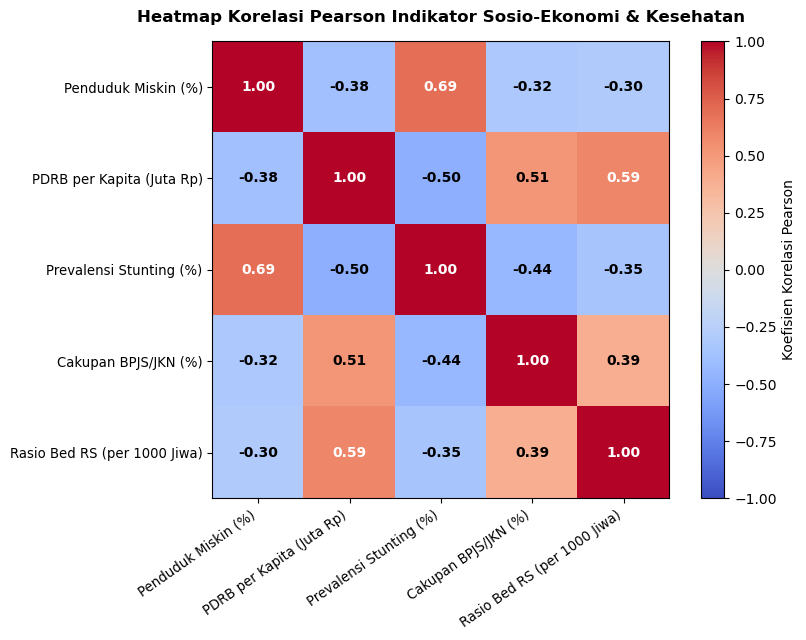

In [7]:
# Visualisasi Matriks Korelasi dengan Heatmap
fig, ax = plt.subplots(figsize=(8.5, 6.5))

# Plot heatmap menggunakan colormap coolwarm
cax = ax.imshow(matriks_korelasi.to_numpy(), cmap='coolwarm', vmin=-1.0, vmax=1.0)

# Menyesuaikan label dan rotasi sumbu agar mudah dibaca
daftar_kolom = list(matriks_korelasi.columns)
ax.set_xticks(range(len(daftar_kolom)))
ax.set_yticks(range(len(daftar_kolom)))
ax.set_xticklabels(daftar_kolom, rotation=35, ha='right', fontsize=9.5)
ax.set_yticklabels(daftar_kolom, fontsize=9.5)

# Menambahkan label angka koefisien korelasi di setiap sel
for i in range(len(daftar_kolom)):
    for j in range(len(daftar_kolom)):
        nilai = matriks_korelasi.iloc[i, j]
        warna = 'white' if abs(nilai) > 0.55 else 'black'
        ax.text(j, i, f"{nilai:.2f}", ha='center', va='center',
                fontsize=10, fontweight='bold', color=warna)

# Menambahkan colorbar dan judul grafik
fig.colorbar(cax, ax=ax, label='Koefisien Korelasi Pearson')
ax.set_title('Heatmap Korelasi Pearson Indikator Sosio-Ekonomi & Kesehatan', 
             fontsize=12, fontweight='bold', pad=14)

fig.tight_layout()
fig.savefig('heatmap_korelasi.png', dpi=160, bbox_inches='tight')
plt.show()


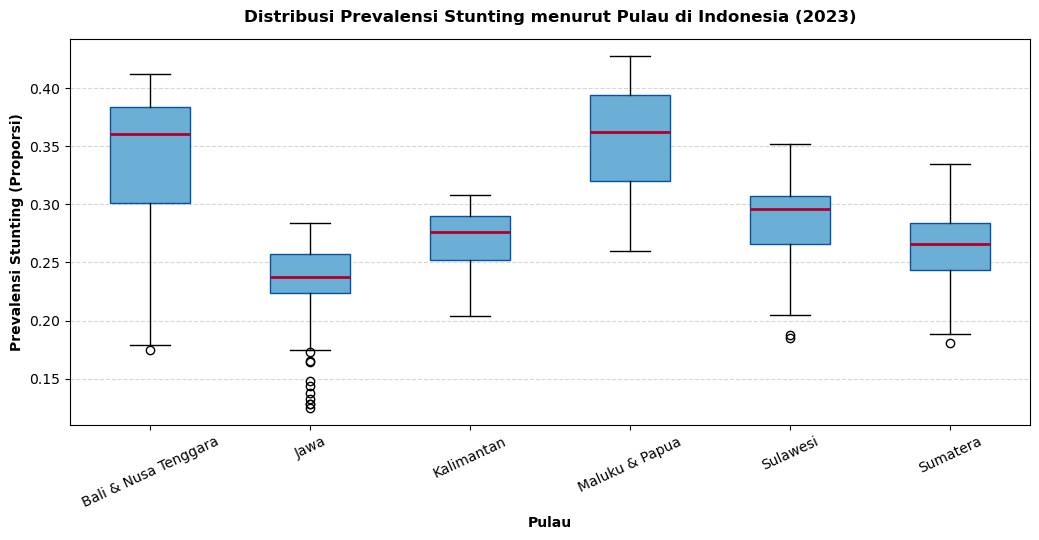

In [8]:
# Visualisasi Boxplot Prevalensi Stunting per Pulau (Tahun 2023)
data_2023 = df_master.loc[df_master['Tahun'].eq(2023)]
daftar_pulau = sorted(data_2023['Pulau'].dropna().unique())

# Mengambil sebaran stunting per pulau
nilai_stunting_pulau = [
    data_2023.loc[data_2023['Pulau'].eq(p), 'Prevalensi Stunting (%)'].dropna()
    for p in daftar_pulau
]

fig, ax = plt.subplots(figsize=(10.5, 5.5))
bp = ax.boxplot(nilai_stunting_pulau, tick_labels=daftar_pulau, patch_artist=True)

# Kustomisasi estetika boxplot
for box in bp['boxes']:
    box.set_facecolor('#6baed6')
    box.set_edgecolor('#08519c')
for median in bp['medians']:
    median.set_color('#b10026')
    median.set_linewidth(2)

ax.set_title('Distribusi Prevalensi Stunting menurut Pulau di Indonesia (2023)', 
             fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Pulau', fontsize=10, fontweight='bold')
ax.set_ylabel('Prevalensi Stunting (Proporsi)', fontsize=10, fontweight='bold')
ax.tick_params(axis='x', rotation=25)
ax.grid(axis='y', linestyle='--', alpha=0.5)

fig.tight_layout()
fig.savefig('boxplot_stunting_pulau.png', dpi=160, bbox_inches='tight')
plt.show()


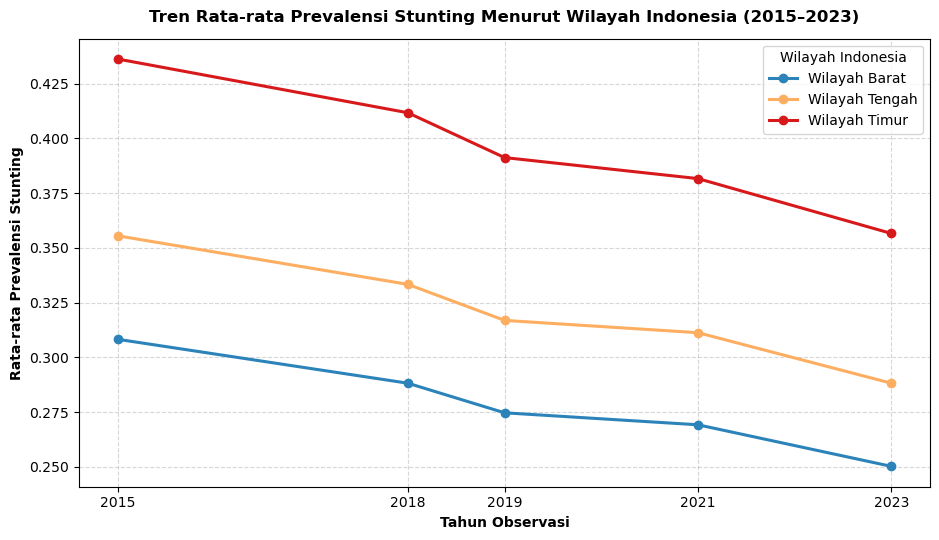

In [9]:
# Visualisasi Line Plot Tren Rata-rata Stunting Berdasarkan Wilayah Indonesia (2015-2023)
tren_stunting = (df_master.groupby(['Tahun', 'Wilayah Indonesia'], as_index=False)['Prevalensi Stunting (%)']
                .mean())

fig, ax = plt.subplots(figsize=(9.5, 5.5))

skema_warna = {'Barat': '#2b83ba', 'Tengah': '#fdae61', 'Timur': '#d7191c'}
for wilayah, sub in tren_stunting.groupby('Wilayah Indonesia'):
    ax.plot(sub['Tahun'], sub['Prevalensi Stunting (%)'],
            marker='o', markersize=6, linewidth=2.2, label=f'Wilayah {wilayah}',
            color=skema_warna.get(wilayah, None))

ax.set_title('Tren Rata-rata Prevalensi Stunting Menurut Wilayah Indonesia (2015–2023)', 
             fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Tahun Observasi', fontsize=10, fontweight='bold')
ax.set_ylabel('Rata-rata Prevalensi Stunting', fontsize=10, fontweight='bold')
ax.set_xticks(sorted(df_master['Tahun'].unique()))
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(title='Wilayah Indonesia', frameon=True)

fig.tight_layout()
fig.savefig('tren_stunting_wilayah.png', dpi=160, bbox_inches='tight')
plt.show()


**Interpretasi Task 5:**  
- **Outlier:** Sebanyak 41 daerah outlier pada PDRB per kapita dan 58 daerah outlier pada kepadatan penduduk mencerminkan disparitas pembangunan yang berpusat di kota-kota besar serta kawasan industri/pertambangan.
- **Korelasi:** Analisis Pearson menunjukkan korelasi positif yang kuat antara `Penduduk Miskin (%)` dan `Prevalensi Stunting (%)` ($r = 0,69$), serta korelasi negatif antara ketersediaan faskes (`Rasio Bed RS`) terhadap stunting ($r = -0,35$).
- **Visualisasi:** Boxplot memperlihatkan bahwa pulau-pulau kawasan timur (seperti Maluku dan Papua) memiliki sebaran stunting yang lebih tinggi dibandingkan Jawa dan Sumatera. Namun demikian, line plot mengonfirmasi bahwa seluruh wilayah Indonesia berhasil mencatatkan tren penurunan rata-rata stunting secara berkesinambungan sejak 2015 hingga 2023.


# Bab III. Kesimpulan Analisis

Berdasarkan seluruh alur analisis Data Wrangling yang telah dilakukan:
1. **Struktur Data Bersih & Terstandarisasi:** Dataset master berhasil dipisahkan menjadi tabel dimensi wilayah unik (514 baris), tabel fakta indikator (2.570 baris), format *tidy* (`dataset long format.csv` dengan 59.110 baris), serta panel data stunting yang siap pakai untuk pemodelan lebih lanjut.
2. **Identifikasi Wilayah Prioritas:** Terdapat 87 kabupaten/kota yang mengalami kondisi darurat ganda kemiskinan (>10%) dan stunting tinggi (>30%) di tahun 2023. Wilayah-wilayah ini perlu diprioritaskan dalam program intervensi spesifik pemerintah.
3. **Penyebab Struktural Stunting:** Korelasi positif yang kuat antara kemiskinan dan stunting ($r = 0,69$) membuktikan bahwa penanganan stunting tidak dapat dipisahkan dari program penanggulangan kemiskinan dan pemenuhan jaminan sosial kesehatan (BPJS).
4. **Disparitas Spasial Antar-Wilayah:** Meskipun tren stunting nasional terus menurun dari tahun 2015 hingga 2023, ketimpangan antara Kawasan Barat, Tengah, dan Timur Indonesia masih lebar, sehingga alokasi fasilitas kesehatan dan infrastruktur dasar harus difokuskan pada daerah tertinggal di Indonesia Timur.
